<a href="https://colab.research.google.com/github/ensogma/dls/blob/main/language_modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

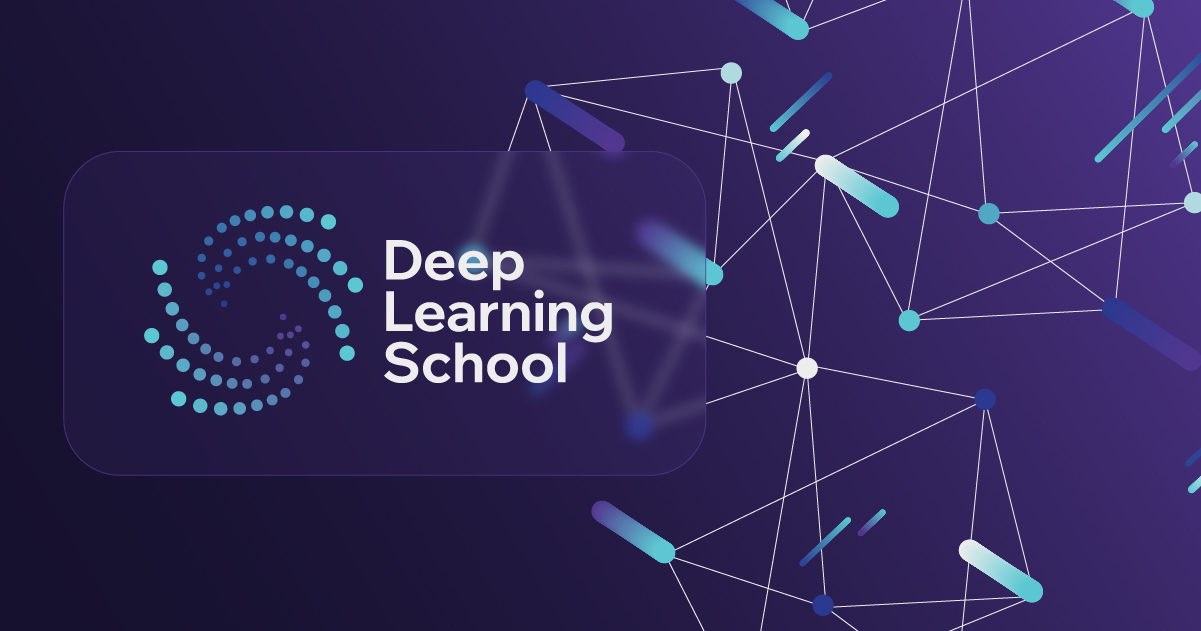

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Обучение языковой модели с помощью LSTM </b></h1>


В этом задании Вам предстоит обучить языковую модель с помощью рекуррентной нейронной сети. В отличие от семинарского занятия, Вам необходимо будет работать с отдельными словами, а не буквами.


Установим модуль ```datasets```, чтобы нам проще было работать с данными.

In [1]:
!pip install datasets

Импорт необходимых библиотек

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List

import seaborn
seaborn.set(palette='summer')

In [3]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных

Воспользуемся датасетом imdb. В нем хранятся отзывы о фильмах с сайта imdb. Загрузим данные с помощью функции ```load_dataset```

In [5]:
# Загрузим датасет
dataset = load_dataset('stanfordnlp/imdb')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [6]:
dataset['train']['text'][0]

'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, ev

In [ ]:
dataset['unsupervised'][0]

{'text': 'This is just a precious little diamond. The play, the script are excellent. I cant compare this movie with anything else, maybe except the movie "Leon" wonderfully played by Jean Reno and Natalie Portman. But... What can I say about this one? This is the best movie Anne Parillaud has ever played in (See please "Frankie Starlight", she\'s speaking English there) to see what I mean. The story of young punk girl Nikita, taken into the depraved world of the secret government forces has been exceptionally over used by Americans. Never mind the "Point of no return" and especially the "La femme Nikita" TV series. They cannot compare the original believe me! Trash these videos. Buy this one, do not rent it, BUY it. BTW beware of the subtitles of the LA company which "translate" the US release. What a disgrace! If you cant understand French, get a dubbed version. But you\'ll regret later :)',
 'label': -1}

### Препроцессинг данных и создание словаря (1 балл)

Далее вам необходмо самостоятельно произвести препроцессинг данных и получить словарь или же просто ```set``` строк. Что необходимо сделать:

1. Разделить отдельные тренировочные примеры на отдельные предложения с помощью функции ```sent_tokenize``` из бибилиотеки ```nltk```. Каждое отдельное предложение будет одним тренировочным примером.
2. Оставить только те предложения, в которых меньше ```word_threshold``` слов.
3. Посчитать частоту вхождения каждого слова в оставшихся предложениях. Для деления предлоения на отдельные слова удобно использовать функцию ```word_tokenize```.
4. Создать объект ```vocab``` класса ```set```, положить в него служебные токены '\<unk\>', '\<bos\>', '\<eos\>', '\<pad\>' и vocab_size самых частовстречающихся слов.   

In [7]:
sentences = []
word_threshold = 128

# Получить отдельные предложения и поместить их в sentences

for sentence in tqdm(dataset['train']['text']):
    sentences.extend(
        [x.lower() for x in sent_tokenize(sentence,language='english') if len(x) < word_threshold]
    )

  0%|          | 0/25000 [00:00<?, ?it/s]

In [8]:
print("Всего предложений:", len(sentences))

Всего предложений: 177208


Посчитаем для каждого слова его встречаемость.

In [9]:
words = Counter()

# Расчет встречаемости слов
for sentence in sentences:
    for word in word_tokenize(sentence):
        words[word]+=1

Добавим в словарь ```vocab_size``` самых встречающихся слов.

In [10]:
vocab = set()
vocab_size = 40000

# Наполнение словаря
words = dict(sorted(words.items(),key=lambda x:x[1],reverse=True))
for k,v in words.items():
    vocab.add(k)
    if len(vocab) == vocab_size:
        break
vocab.update(['<unk>','<bos>','<eos>','<pad>'])

In [ ]:
len(vocab)

40004

In [11]:
assert '<unk>' in vocab
assert '<bos>' in vocab
assert '<eos>' in vocab
assert '<pad>' in vocab
assert len(vocab) == vocab_size + 4

In [12]:
print("Всего слов в словаре:", len(vocab))

Всего слов в словаре: 40004


### Подготовка датасета (1 балл)

Далее, как и в семинарском занятии, подготовим датасеты и даталоадеры.

В классе ```WordDataset``` вам необходимо реализовать метод ```__getitem__```, который будет возвращать сэмпл данных по входному idx, то есть список целых чисел (индексов слов).

Внутри этого метода необходимо добавить служебные токены начала и конца последовательности, а также токенизировать соответствующее предложение с помощью ```word_tokenize``` и сопоставить ему индексы из ```word2ind```.

In [13]:
word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

In [14]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        tokenized_sentence = []
        # Допишите код здесь
        tokenized_sentence.append(self.bos_id)
        tokenized_sentence+=[word2ind.get(word,self.unk_id) for word in word_tokenize(self.data[idx])]
        tokenized_sentence.append(self.eos_id)

        return tokenized_sentence

    def __len__(self) -> int:
        return len(self.data)

In [15]:
def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>']) -> torch.Tensor:
    seq_lens = [len(x) for x in input_batch]
    max_seq_len = max(seq_lens)

    new_batch = []
    for sequence in input_batch:
        for _ in range(max_seq_len - len(sequence)):
            sequence.append(pad_id)
        new_batch.append(sequence)

    sequences = torch.LongTensor(new_batch).to(device)

    new_batch = {
        'input_ids': sequences[:,:-1],
        'target_ids': sequences[:,1:]
    }

    return new_batch

In [16]:
train_sentences, temp_sentences = train_test_split(sentences, test_size=0.2, random_state=42)
eval_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

train_dataset = WordDataset(train_sentences)
eval_dataset = WordDataset(eval_sentences)
test_dataset = WordDataset(test_sentences)

batch_size = 128

train_dataloader = DataLoader(
    train_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

test_dataloader = DataLoader(
    test_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Обучение и архитектура модели

Вам необходимо на практике проверить, что влияет на качество языковых моделей. В этом задании нужно провести серию экспериментов с различными вариантами языковых моделей и сравнить различия в конечной перплексии на тестовом множестве.

Возмоэные идеи для экспериментов:

* Различные RNN-блоки, например, LSTM или GRU. Также можно добавить сразу несколько RNN блоков друг над другом с помощью аргумента num_layers. Вам поможет официальная документация [здесь](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
* Различные размеры скрытого состояния. Различное количество линейных слоев после RNN-блока. Различные функции активации.
* Добавление нормализаций в виде Dropout, BatchNorm или LayerNorm
* Различные аргументы для оптимизации, например, подбор оптимального learning rate или тип алгоритма оптимизации SGD, Adam, RMSProp и другие
* Любые другие идеи и подходы

После проведения экспериментов необходимо составить таблицу результатов, в которой описан каждый эксперимент и посчитана перплексия на тестовом множестве.

Учтите, что эксперименты, которые различаются, например, только размером скрытого состояния или количеством линейных слоев считаются, как один эксперимент.

Успехов!

### Функция evaluate (1 балл)

Заполните функцию ```evaluate```

In [17]:
def evaluate(model, criterion, dataloader) -> float:
    model.eval()
    perplexity = []
    with torch.no_grad():
        for batch in dataloader:
            logits = model(batch['input_ids']).flatten(start_dim=0,end_dim=1)# Посчитайте логиты предсказаний следующих слов
            loss = criterion(logits, batch['target_ids'].flatten())
            perplexity.append(torch.exp(loss).item())

    perplexity = sum(perplexity) / len(perplexity)

    return perplexity

### Train loop (1 балл)

Напишите функцию для обучения модели.

In [18]:
def train_model(num_epoch,train_dataloader,model,optimizer,criterion,eval_dataloader):
    # Напишите код здесь

    losses = []
    perplexities = []
    for epoch in range(num_epoch):
        epoch_losses=[]
        model.train()
        for batch in tqdm(train_dataloader,desc=f'training epoch {epoch}:'):
            optimizer.zero_grad()
            logits = model(batch['input_ids']).flatten(start_dim=0,end_dim=1)
            loss = criterion(logits,batch['target_ids'].flatten())
            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())

        losses.append(sum(epoch_losses)/len(epoch_losses))
        perplexities.append(evaluate(model,criterion,eval_dataloader))

    return losses,perplexities

### Первый эксперимент (2 балла)

Определите архитектуру модели и обучите её.

базовая RNN модель

In [ ]:
class LanguageModel(nn.Module):
    def __init__(self, hidden_dim:int, vocab_size:int):
        super().__init__()

        # Опишите свою нейронную сеть здесь
        self.embedding = nn.Embedding(vocab_size,hidden_dim)
        self.rnn = nn.RNN(hidden_dim,hidden_dim,batch_first=True)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        # А тут опишите forward pass модели
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

In [ ]:
# Обучите модель здесь
model = LanguageModel(hidden_dim=256,vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model.parameters())

In [ ]:
losses,perplexities = train_model(5,train_dataloader,model,optimizer,criterion,eval_dataloader)

training epoch 0::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 1::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 2::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 3::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 4::   0%|          | 0/1108 [00:00<?, ?it/s]

In [ ]:
evaluate(model,criterion,test_dataloader)

105.85951068246965

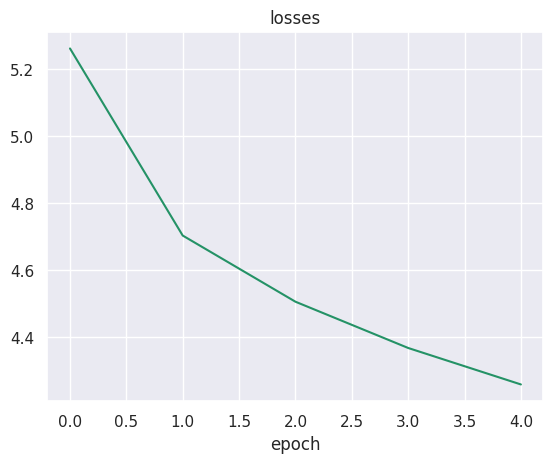

In [ ]:
plt.plot(np.arange(len(losses)), losses)
plt.title('losses')
plt.xlabel('epoch')
plt.show()

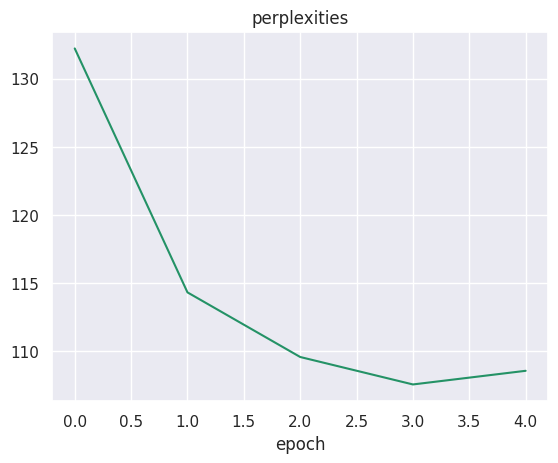

In [ ]:
plt.plot(np.arange(len(perplexities)), perplexities)
plt.title('perplexities')
plt.xlabel('epoch')
plt.show()

### Второй эксперимент (2 балла)

Попробуйте что-то поменять в модели или в пайплайне обучения, идеи для экспериментов можно подсмотреть выше.

будем использовать lstm вместо дефолт rnn

In [70]:
# Проведите второй эксперимент
class LanguageModel_LSTM(nn.Module):
    def __init__(self, hidden_dim:int, vocab_size:int):
        super().__init__()

        # Опишите свою нейронную сеть здесь
        self.embedding = nn.Embedding(vocab_size,hidden_dim)
        self.lstm = nn.LSTM(hidden_dim,hidden_dim,batch_first=True)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        # А тут опишите forward pass модели
        embeddings = self.embedding(input_batch)
        output, _ = self.lstm(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

In [ ]:
# Обучите модель здесь
model_lstm = LanguageModel_LSTM(hidden_dim=256,vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_lstm.parameters())

In [ ]:
losses,perplexities = train_model(5,train_dataloader,model_lstm,optimizer,criterion,eval_dataloader)

training epoch 0::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 1::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 2::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 3::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 4::   0%|          | 0/1108 [00:00<?, ?it/s]

In [ ]:
evaluate(model_lstm,criterion,test_dataloader)

94.17189530846026

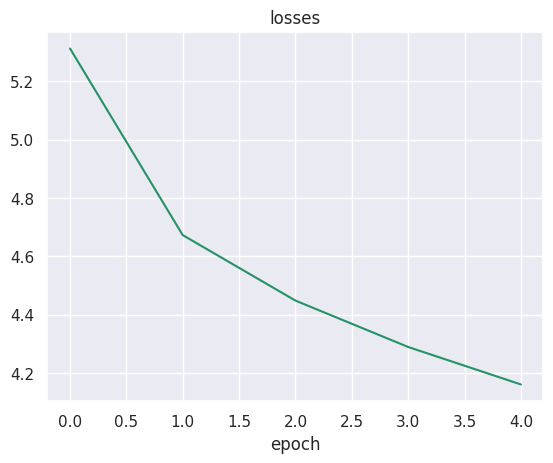

In [ ]:
plt.plot(np.arange(len(losses)), losses)
plt.title('losses')
plt.xlabel('epoch')
plt.show()

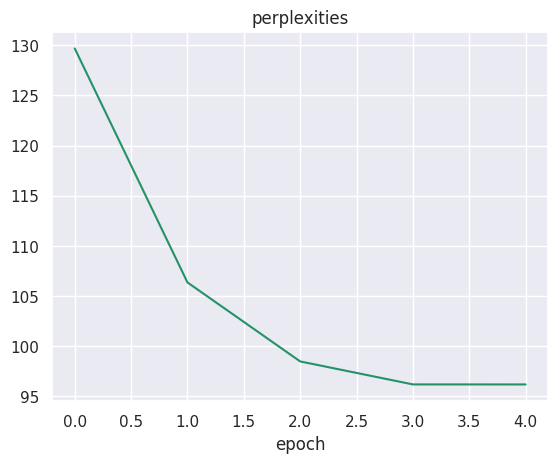

In [ ]:
plt.plot(np.arange(len(perplexities)), perplexities)
plt.title('perplexities')
plt.xlabel('epoch')
plt.show()

# 3й эксперимент

увеличим кол-во lstm слоев

In [29]:
class LanguageModel_LSTM_with_layer_management(nn.Module):
    def __init__(self, hidden_dim:int, vocab_size:int, num_layers:int):
        super().__init__()

        # Опишите свою нейронную сеть здесь
        self.embedding = nn.Embedding(vocab_size,hidden_dim)
        self.lstm = nn.LSTM(hidden_dim,hidden_dim,num_layers,batch_first=True)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        # А тут опишите forward pass модели
        embeddings = self.embedding(input_batch)
        output, _ = self.lstm(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

In [30]:
# Обучите модель здесь
model_lstm_wlm = LanguageModel_LSTM_with_layer_management(hidden_dim=256,vocab_size=len(vocab), num_layers=3).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_lstm_wlm.parameters())

In [31]:
losses,perplexities = train_model(5,train_dataloader,model_lstm_wlm,optimizer,criterion,eval_dataloader)

training epoch 0::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 1::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 2::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 3::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 4::   0%|          | 0/1108 [00:00<?, ?it/s]

In [33]:
evaluate(model_lstm_wlm,criterion,test_dataloader)

116.61877798176498

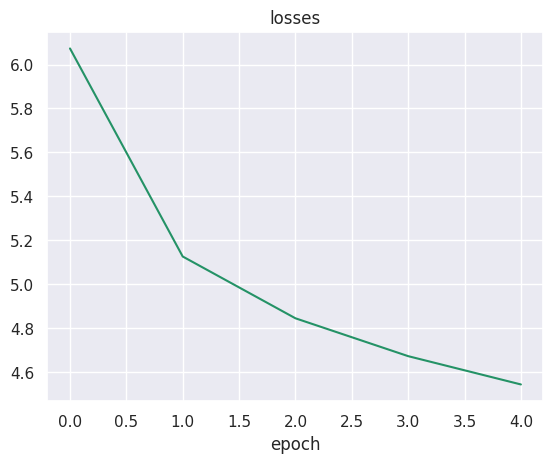

In [34]:
plt.plot(np.arange(len(losses)), losses)
plt.title('losses')
plt.xlabel('epoch')
plt.show()

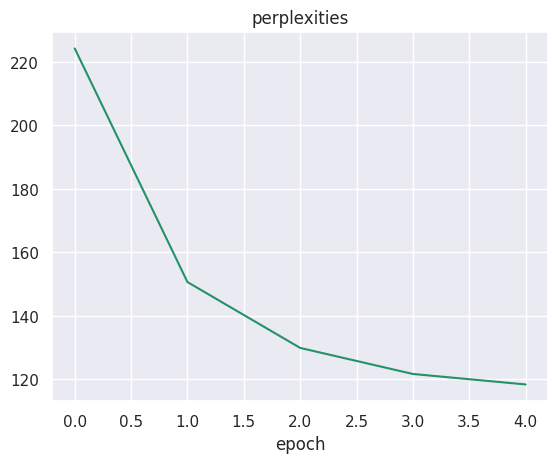

In [35]:
plt.plot(np.arange(len(perplexities)), perplexities)
plt.title('perplexities')
plt.xlabel('epoch')
plt.show()

# 4й эксперимент

вместе с увелечением lstm слоев добавим дропаут в lstm слои

In [36]:
class LanguageModel_LSTM_with_layer_management_and_dropout(nn.Module):
    def __init__(self, hidden_dim:int, vocab_size:int, num_layers:int):
        super().__init__()

        # Опишите свою нейронную сеть здесь
        self.embedding = nn.Embedding(vocab_size,hidden_dim)
        self.lstm = nn.LSTM(hidden_dim,hidden_dim,num_layers,batch_first=True,dropout=0.1)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        # А тут опишите forward pass модели
        embeddings = self.embedding(input_batch)
        output, _ = self.lstm(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

In [37]:
# Обучите модель здесь
model_lstm_wlmad = LanguageModel_LSTM_with_layer_management_and_dropout(hidden_dim=256,vocab_size=len(vocab), num_layers=2).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_lstm_wlmad.parameters())

In [38]:
losses,perplexities = train_model(5,train_dataloader,model_lstm_wlmad,optimizer,criterion,eval_dataloader)

training epoch 0::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 1::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 2::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 3::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 4::   0%|          | 0/1108 [00:00<?, ?it/s]

In [39]:
evaluate(model_lstm_wlmad,criterion,test_dataloader)

100.22835474906208

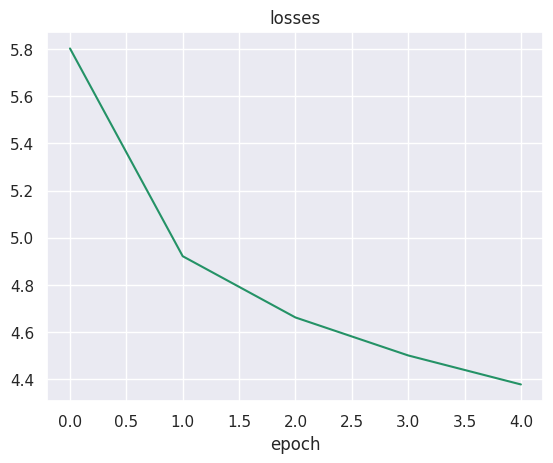

In [40]:
plt.plot(np.arange(len(losses)), losses)
plt.title('losses')
plt.xlabel('epoch')
plt.show()

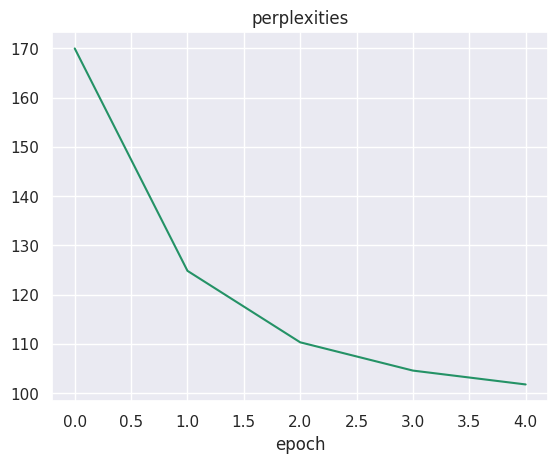

In [41]:
plt.plot(np.arange(len(perplexities)), perplexities)
plt.title('perplexities')
plt.xlabel('epoch')
plt.show()

In [55]:
def generate_sentence(model, seed_text: str = "", max_len: int = 30, temperature: float = 1.0) -> str:
    """
    Generates a sentence token by token using the trained language model.

    Args:
        model: Trained LanguageModel or LanguageModel_LSTM instance
        seed_text: Optional string to start the generation (e.g., "the movie was")
        max_len: Maximum number of tokens to generate before stopping
        temperature: Controls randomness (1.0 = normal sampling, lower = more predictable, higher = more random)
    """
    model.eval()
    tokens = [word2ind['<bos>']]

    if seed_text:
        # Tokenize seed text
        seed_tokens = [word2ind.get(w, word2ind['<unk>']) for w in word_tokenize(seed_text.lower())]
        tokens.extend(seed_tokens)

    with torch.no_grad():
        for _ in range(max_len):
            input_tensor = torch.LongTensor([tokens]).to(device)

            logits = model(input_tensor)

            last_token_logits = logits[0, -1, :]

            last_token_logits = last_token_logits / max(temperature, 1e-5)

            probs = torch.softmax(last_token_logits, dim=-1)

            next_token_id = torch.multinomial(probs, num_samples=1).item()


            tokens.append(next_token_id)

            if next_token_id == word2ind['<eos>'] or next_token_id == word2ind['<pad>']:
                break

    generated_words = []
    for t_id in tokens:
        word = ind2word[t_id]
        if word in ['<bos>', '<eos>', '<pad>','<unk>']:
            continue
        generated_words.append(word)
    return " ".join(generated_words)


In [58]:
generate_sentence(model_lstm_wlmad,"this movie was")

'this movie was the first plot of the movie and far in quite gory lip in hollywood .'

# 5й эксперимент

уменьшим колво параметров в 2 раза с помощью self.projection.weight = self.embedding.weight. мы так можем сделать так как embedding и projection связаны непосредстенно

In [59]:
class LanguageModel_Ultima(nn.Module):
    def __init__(self, hidden_dim:int, vocab_size:int, num_layers:int):
        super().__init__()

        # Опишите свою нейронную сеть здесь
        self.embedding = nn.Embedding(vocab_size,hidden_dim)
        self.lstm = nn.LSTM(hidden_dim,hidden_dim,num_layers,batch_first=True,dropout=0.1)
        self.linear = nn.Linear(hidden_dim,hidden_dim)
        self.projection = nn.Linear(hidden_dim,vocab_size)

        self.projection.weight = self.embedding.weight

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        # А тут опишите forward pass модели
        embeddings = self.embedding(input_batch)
        output, _ = self.lstm(embeddings)
        output = self.dropout(self.linear(self.non_lin(output)))
        projection = self.projection(self.non_lin(output))

        return projection

In [60]:
# Обучите модель здесь
model_ultima = LanguageModel_Ultima(hidden_dim=256,vocab_size=len(vocab), num_layers=1).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_ultima.parameters())

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1013: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.1 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


In [61]:
losses,perplexities = train_model(5,train_dataloader,model_ultima,optimizer,criterion,eval_dataloader)

training epoch 0::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 1::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 2::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 3::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 4::   0%|          | 0/1108 [00:00<?, ?it/s]

In [62]:
evaluate(model_ultima,criterion,test_dataloader)

100.37355513538388

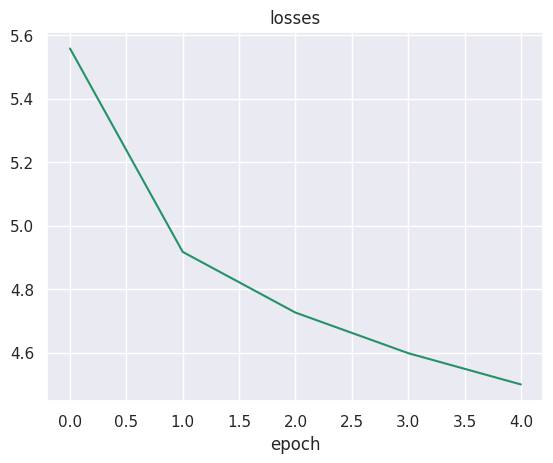

In [63]:
plt.plot(np.arange(len(losses)), losses)
plt.title('losses')
plt.xlabel('epoch')
plt.show()

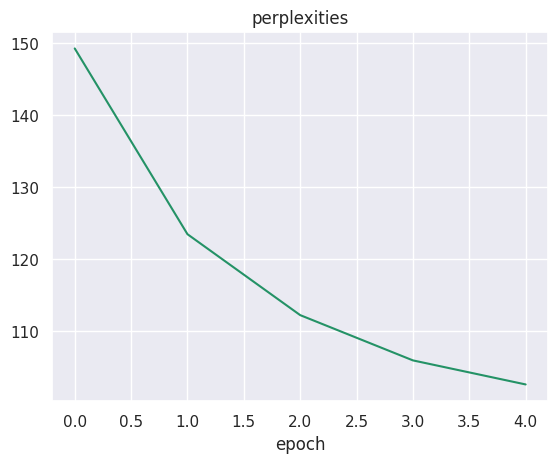

In [64]:
plt.plot(np.arange(len(perplexities)), perplexities)
plt.title('perplexities')
plt.xlabel('epoch')
plt.show()

# 6й эксперимент

возьем лучшую на данный момент модель(lstm) и обучим ее 10 эпох и увеличим параметр hidden_dim в 2 раза.

In [71]:
# Обучите модель здесь
model_astra = LanguageModel_LSTM(hidden_dim=512,vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_astra.parameters())

In [72]:
losses,perplexities = train_model(10,train_dataloader,model_astra,optimizer,criterion,eval_dataloader)

training epoch 0::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 1::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 2::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 3::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 4::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 5::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 6::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 7::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 8::   0%|          | 0/1108 [00:00<?, ?it/s]

training epoch 9::   0%|          | 0/1108 [00:00<?, ?it/s]

In [74]:
evaluate(model_astra,criterion,test_dataloader)

165.64931224576003

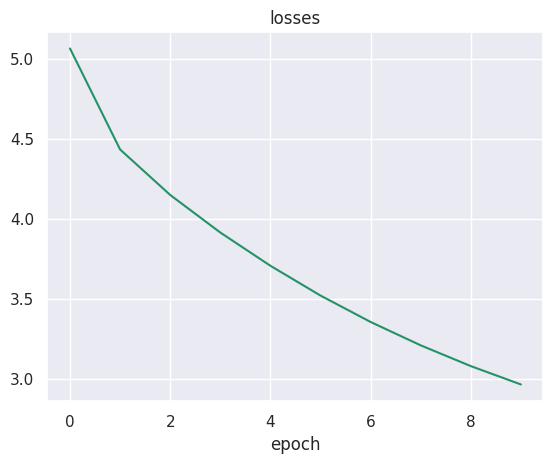

In [75]:
plt.plot(np.arange(len(losses)), losses)
plt.title('losses')
plt.xlabel('epoch')
plt.show()

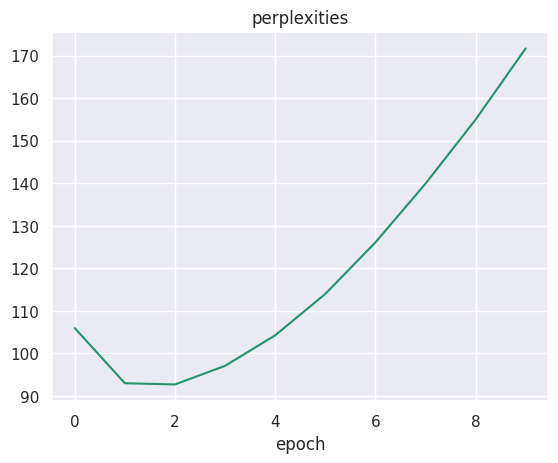

In [76]:
plt.plot(np.arange(len(perplexities)), perplexities)
plt.title('perplexities')
plt.xlabel('epoch')
plt.show()

In [77]:
perplexities

[105.9748659751398,
 93.00479082066379,
 92.7169645570165,
 97.08895769736749,
 104.2600863888967,
 113.98319601155013,
 126.09480258200666,
 139.89981084590335,
 154.9616104235752,
 171.6979218078174]

из-за большого hidden_dim модель переобучилась

### Отчет (2 балла)

Опишите проведенные эксперименты. Сравните перплексии полученных моделей. Предложите идеи по улучшению качества моделей.

в 1ом эксперименте был исользован стандартный подход - rnn. perplexity получилась 105. данное значение мы будем считать бейзлайном.

во 2ом эксперименте я использовал lstm он дал хорошее улучшение перплексии а именно 94.

в 3ем эксперименте я увеличил колво lstm слоев с 1 до 3 но это ухудшило качество.

в 4ом я добавил к 3ей архитектуре dropout и уменьшил кол-во слоев с 3 до 2 и это дало результат лучше бейзлайна но хуже простого lstm

в 5ом я уменьшил кол-во параметров чтобы модель меньше переобучалась но это дало результат хуже чем lstm.

в 6ом я взяо лучшую модель обучал ее 10 эпох и увеличил hidden_dim вдвое но модель переобучилась.

таким образом лучшей оказался стандартный подход с lstm

улучшить можно использовав предобученные эмбеддинги, или проще перейти на BPE. возможно стоит увеличить кол-во слоев и правильно подобрать dropout. борясь со взрывом градиентов к которуму склоны rnn на длинных последовательностях стоит попробовать Gradient Clipping.